# Part 3: Principal Component Analysis

## Q2: Generate a 2D Correlated Gaussian Dataset

In [61]:
import numpy as np
import matplotlib.pyplot as plt

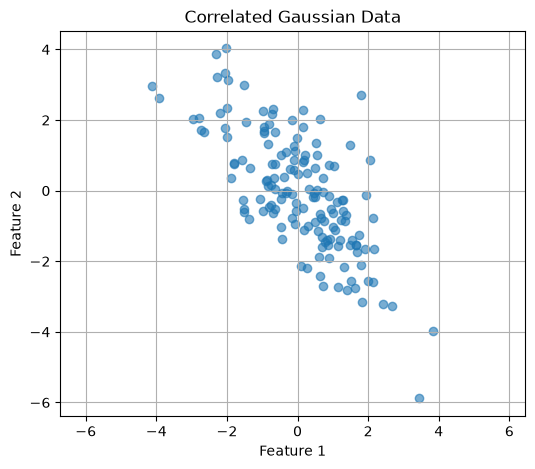

In [62]:
np.random.seed(42)

# Mean and covariance matrix
mean = [0, 0]
cov = [[2, -1.8],
       [-1.8, 3]]

# Generate 150 samples
X = np.random.multivariate_normal(mean, cov, 150)

# Scatter plot
plt.figure(figsize=(6, 5))
plt.scatter(X[:, 0], X[:, 1], alpha=0.6)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Correlated Gaussian Data")
plt.grid(True)
plt.axis("equal")
plt.show()

The scatter plot shows a clear negative correlation between the two features. As Feature 1 increases, Feature 2 tends to decrease. The elongated shape of the data indicates a relatively strong linear relationship.

## Q3: PCA from Scratch

In [63]:
# Step 1: Center the dataset
mean_vector = np.mean(X, axis=0)
X_centered = X - mean_vector

print(mean_vector)

[ 0.05760922 -0.04562851]


In [64]:
# Step 2: Compute the covariance matrix
cov_matrix = np.cov(X_centered, rowvar=False)

print(cov_matrix)

[[ 1.92431262 -1.67284284]
 [-1.67284284  2.80479941]]


In [65]:
# Step 3: Compute eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)

Eigenvalues:
[0.63475331 4.09435873]

Eigenvectors:
[[-0.79199273 -0.61053052]
 [-0.61053052  0.79199273]]


In [66]:
# Sort eigenvalues from largest to smallest
indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[indices]
eigenvectors = eigenvectors[:, indices]

print("Sorted eigenvalues:")
print(eigenvalues)

print("\nPrincipal components:")
print(eigenvectors)

Sorted eigenvalues:
[4.09435873 0.63475331]

Principal components:
[[-0.61053052 -0.79199273]
 [ 0.79199273 -0.61053052]]


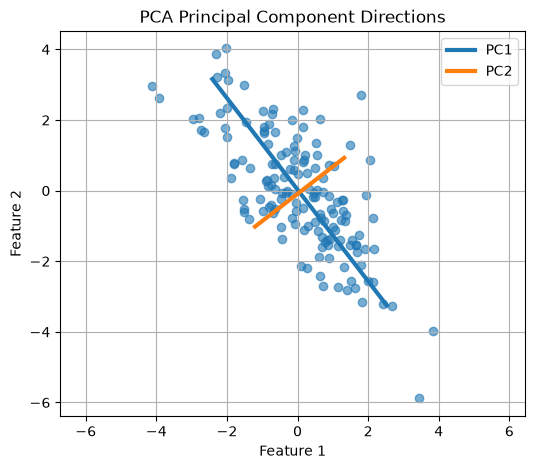

In [67]:
# Step 4: Visualize the principal component directions
plt.figure(figsize=(6, 5))

plt.scatter(X[:, 0], X[:, 1], alpha=0.6)

for i in range(2):
    direction = eigenvectors[:, i]

    # Scale the direction by the square root of the eigenvalue
    scale = 2 * np.sqrt(eigenvalues[i])

    start = mean_vector - scale * direction
    end = mean_vector + scale * direction

    plt.plot(
        [start[0], end[0]],
        [start[1], end[1]],
        linewidth=3,
        label=f"PC{i+1}"
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("PCA Principal Component Directions")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

The PCA result matches the shape of the scatter plot. PC1 points along the main direction of the data, where the points are spread out the most. This is consistent with Q1, since the variance along a direction is given by uᵀΣu. PC2 is perpendicular to PC1 and represents the smaller variation across that main direction.

## Q4: Explained Variance

In [68]:
# Compute explained variance ratio
explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

print("Explained variance ratio:")
print(explained_variance_ratio)

print(f"PC1: {explained_variance_ratio[0] * 100:.2f}%")
print(f"PC2: {explained_variance_ratio[1] * 100:.2f}%")

Explained variance ratio:
[0.86577749 0.13422251]
PC1: 86.58%
PC2: 13.42%


PC1 explains 86.58% of the total variance, while PC2 explains 13.42%. This means that if I reduce the data from two dimensions to one by keeping only PC1, about 86% of the variation is still preserved. The benefit is a simpler representation of the data, but about 14% of the variance is lost.